# Notebook 1 – CNN Deep Dive



In [66]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from scipy import signal

torch.manual_seed(0); np.random.seed(0)
plt.rcParams["figure.dpi"] = 100
print("torch", torch.__version__)

import os
import numpy as np
import pandas as pd
from PIL import Image

DATA_DIR_CANDIDATES = ["image_data", os.path.join("image_data (1)", "image_data"), "image_data (1)"]
DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if os.path.isdir(os.path.join(path, "fashion_mnist"))), None)
if DATA_DIR is None:
    raise FileNotFoundError("Fashion-MNIST data not found. Expected image_data/fashion_mnist or image_data (1)/image_data/fashion_mnist next to this notebook.")
FMNIST_DIR = os.path.join(DATA_DIR, "fashion_mnist")

_labels = pd.read_csv(os.path.join(FMNIST_DIR, "labels.csv"))
FMNIST_CLASSES = _labels.drop_duplicates("label").sort_values("label")["class_name"].tolist()

def load_fashion_mnist(train_per_class=800, test_per_class=200, seed=0):
    """Read PNG files from image_data/fashion_mnist. Returns shuffled uint8 images (N, 28, 28) and int labels
    for a class-balanced subset of the official train and test folders (small enough for a CPU-only machine)."""
    rng = np.random.default_rng(seed)
    out = []
    for split, per_class in [("train", train_per_class), ("test", test_per_class)]:
        df = _labels[_labels["split"] == split]
        df = pd.concat([df[df["label"] == k].sample(per_class, random_state=seed) for k in sorted(df["label"].unique())])
        df = df.iloc[rng.permutation(len(df))]
        imgs = np.stack([np.array(Image.open(os.path.join(FMNIST_DIR, "..", p))) for p in df["path"]])
        out += [imgs.astype(np.uint8), df["label"].to_numpy().astype(np.int64)]
    return out  # X_train, y_train, X_test, y_test

torch 2.14.0+cpu


## 1. Image Representation and Pixels

To a computer an image is just a **grid of numbers**. Each cell of the grid is a **pixel** (picture element) and its number says how bright that location is. Below, a real 8×8 handwritten digit is shown twice: as a picture and as the numbers behind it.

shape: (8, 8)  dtype: float64  min: 0.0  max: 15.0


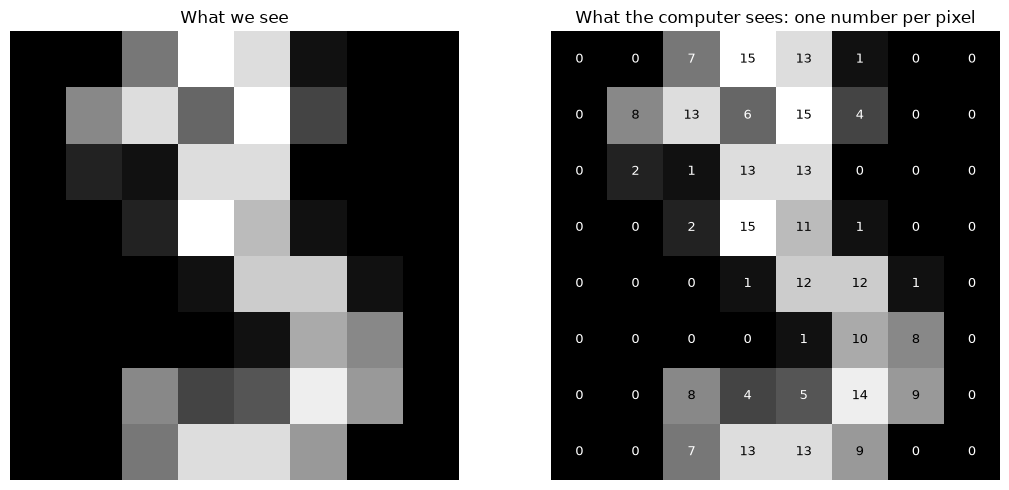

In [67]:
digit = load_digits().images[3]            # 8x8 array; the scale runs 0..16 (0 = no ink, 16 = darkest ink), this digit's maximum is 15
print("shape:", digit.shape, " dtype:", digit.dtype, " min:", digit.min(), " max:", digit.max())

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(digit, cmap="gray"); ax[0].set_title("What we see"); ax[0].axis("off")
ax[1].imshow(digit, cmap="gray")
for (i, j), v in np.ndenumerate(digit):
    ax[1].text(j, i, int(v), ha="center", va="center", color="white" if v < 8 else "black", fontsize=9)
ax[1].set_title("What the computer sees: one number per pixel"); ax[1].axis("off")
plt.tight_layout(); plt.show()

Two conventions you will meet constantly:

* **Integer images** store each pixel as an 8-bit integer `0…255` (`uint8`): 0 = black, 255 = white.
* **Float images** (what neural networks want) store pixels as real numbers, typically scaled to `0…1` or standardised to mean 0.

Real datasets are bigger than 8×8. Fashion-MNIST images are 28×28:

loaded from PNG files -> train: (8000, 28, 28) uint8   test: (2000, 28, 28)
pixel range: 0 to 255


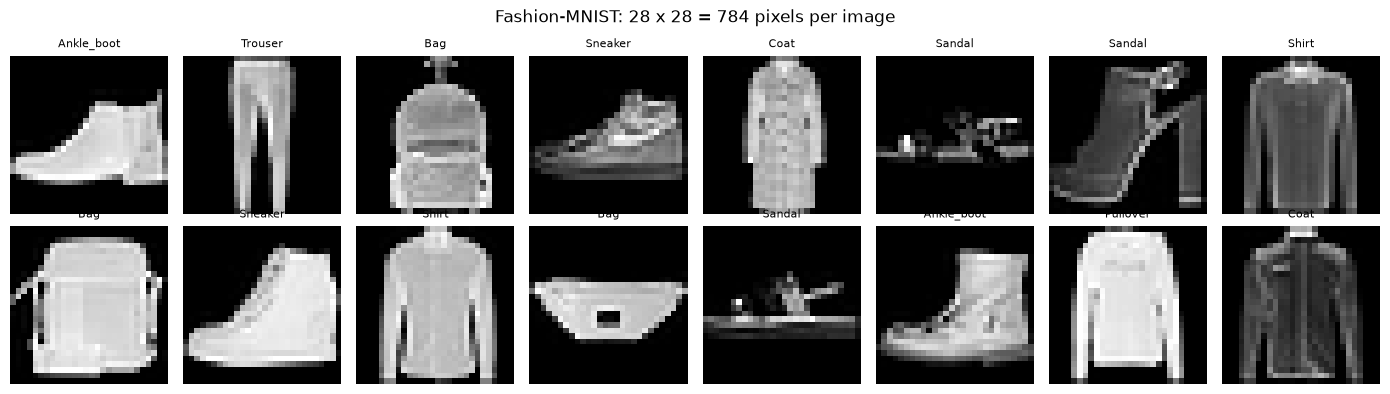

In [68]:
X_train, y_train, X_test, y_test = load_fashion_mnist()
print("loaded from PNG files -> train:", X_train.shape, X_train.dtype, "  test:", X_test.shape)
print("pixel range:", X_train.min(), "to", X_train.max())

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(X_train[i], cmap="gray"); ax.set_title(FMNIST_CLASSES[y_train[i]], fontsize=8); ax.axis("off")
plt.suptitle("Fashion-MNIST: 28 x 28 = 784 pixels per image"); plt.tight_layout(); plt.show()

## 2. Channels: Grayscale vs. RGB

A **channel** is one 2-D grid of numbers covering the whole image.

* **Grayscale** image: **1 channel** (brightness only). Shape `(H, W)` or `(H, W, 1)`.
* **RGB** image: **3 channels**, Red, Green and Blue brightness for each pixel. Shape `(H, W, 3)`. Mixing the three gives every colour.

An RGB image therefore carries 3× as many numbers as a grayscale image of the same height and width.

RGB image shape (H, W, C): (427, 640, 3)  dtype: uint8
One pixel at row 200, col 300 -> [R, G, B] = [47 23 23]


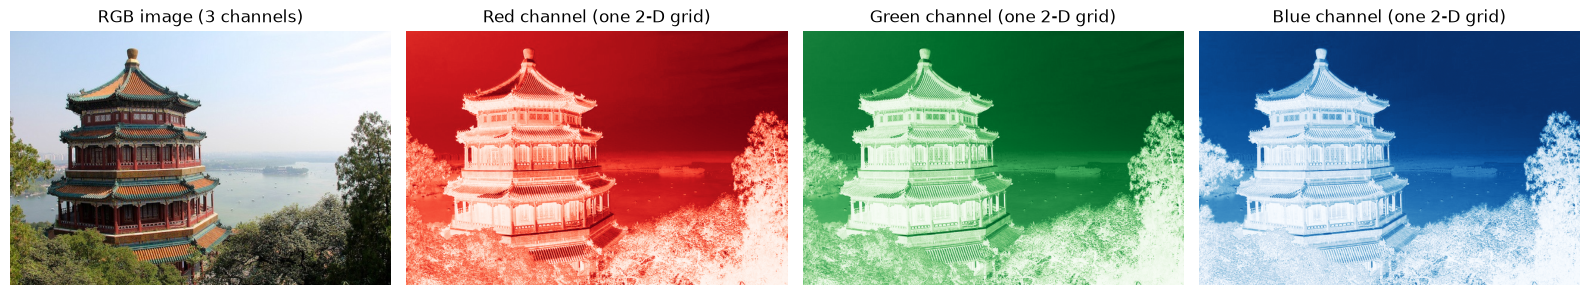

In [69]:
china = np.array(Image.open(os.path.join(DATA_DIR, "rgb_samples", "china.jpg")))
flower = np.array(Image.open(os.path.join(DATA_DIR, "rgb_samples", "flower.jpg")))
img = china
print("RGB image shape (H, W, C):", img.shape, " dtype:", img.dtype)
print("One pixel at row 200, col 300 -> [R, G, B] =", img[200, 300])

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
ax[0].imshow(img); ax[0].set_title("RGB image (3 channels)")
for k, (name, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")]):
    ax[k + 1].imshow(img[:, :, k], cmap=cmap, vmin=0, vmax=255); ax[k + 1].set_title(f"{name} channel (one 2-D grid)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

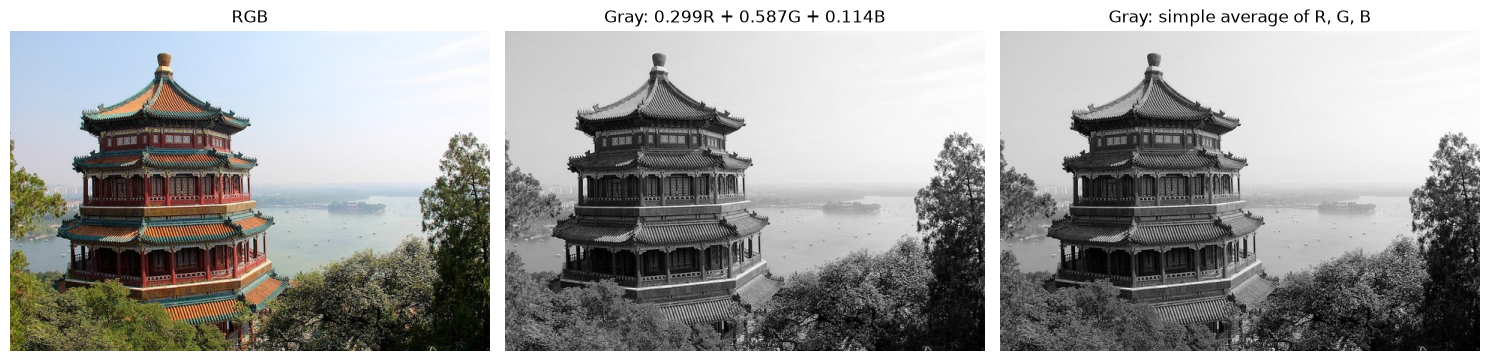

RGB memory:  0.82 MB   |  grayscale (uint8) memory: 0.27 MB
Largest difference between the two grayscale versions: 23.8 intensity levels


In [70]:
# RGB -> grayscale. The standard luminance formula weights green most because the eye is most sensitive to it.
gray_weighted = (0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2])
gray_mean = img.mean(axis=2)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].imshow(img); ax[0].set_title("RGB")
ax[1].imshow(gray_weighted, cmap="gray"); ax[1].set_title("Gray: 0.299R + 0.587G + 0.114B")
ax[2].imshow(gray_mean, cmap="gray"); ax[2].set_title("Gray: simple average of R, G, B")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

print(f"RGB memory:  {img.nbytes / 1e6:.2f} MB   |  grayscale (uint8) memory: {gray_weighted.astype(np.uint8).nbytes / 1e6:.2f} MB")
print(f"Largest difference between the two grayscale versions: {np.abs(gray_weighted - gray_mean).max():.1f} intensity levels")

Channel order matters. Some libraries (OpenCV) store **BGR** instead of RGB; mixing them up silently swaps colours:

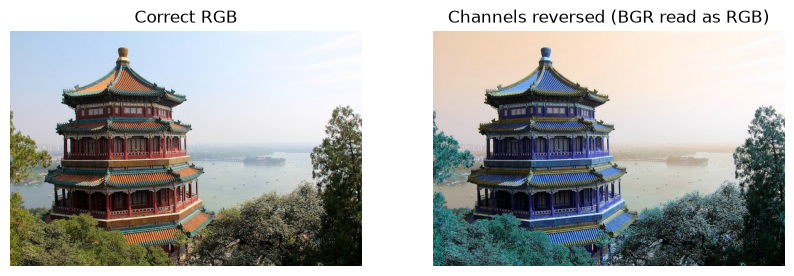

In [71]:
bgr_as_rgb = img[:, :, ::-1]      # reverse the channel axis
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].imshow(img); ax[0].set_title("Correct RGB"); ax[1].imshow(bgr_as_rgb); ax[1].set_title("Channels reversed (BGR read as RGB)")
for a in ax: a.axis("off")
plt.show()

## 3. Image Tensors

A **tensor** is simply an n-dimensional array. Image tensors differ between libraries in *where the channel axis sits*:

| Layout | Meaning | Used by |
|---|---|---|
| **HWC** | (Height, Width, Channels) | NumPy / PIL / matplotlib / OpenCV / TensorFlow |
| **CHW** | (Channels, Height, Width) | **PyTorch** for a single image |
| **NCHW** | (Batch, Channels, Height, Width) | **PyTorch** for a batch (what `Conv2d` expects) |

In [72]:
t = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0     # HWC uint8 -> CHW float in [0, 1]
batch = t.unsqueeze(0)                                          # CHW -> NCHW (a batch of one image)

print("NumPy (H, W, C)  :", img.shape, img.dtype)
print("Tensor (C, H, W) :", tuple(t.shape), t.dtype, f"range [{t.min():.2f}, {t.max():.2f}]")
print("Batch (N, C, H, W):", tuple(batch.shape))
print("\nRed channel identical after the permute?", np.allclose(t[0].numpy() * 255, img[:, :, 0]))

# A Fashion-MNIST mini-batch: 64 grayscale images
xb = torch.from_numpy(X_train[:64]).float().div(255).unsqueeze(1)   # add the channel axis
print("Fashion-MNIST batch (N, C, H, W):", tuple(xb.shape))

NumPy (H, W, C)  : (427, 640, 3) uint8
Tensor (C, H, W) : (3, 427, 640) torch.float32 range [0.00, 1.00]
Batch (N, C, H, W): (1, 3, 427, 640)

Red channel identical after the permute? True
Fashion-MNIST batch (N, C, H, W): (64, 1, 28, 28)


## 4. Convolution, Kernels and Feature Maps (by hand with NumPy)

A **kernel** (or **filter**) is a small grid of numbers, e.g. 3×3. **Convolution** slides the kernel across the image. At every position it:

1. takes the image patch under the kernel,
2. **multiplies** patch and kernel **element by element**,
3. **sums** the products into **one number**,
4. writes that number into the output grid.

The output grid is the **feature map**: it records *how strongly the pattern the kernel looks for is present at each location.*

### A tiny example you can verify with a calculator

A 6×6 image with a dark left half and a bright right half (a vertical edge), and a classic **vertical-edge kernel** (negative on the left, positive on the right):

In [73]:
tiny = np.array([[0, 0, 0, 9, 9, 9]] * 6, dtype=float)     # 6x6 image, vertical edge between columns 2 and 3
kernel = np.array([[-1, 0, 1],
                   [-1, 0, 1],
                   [-1, 0, 1]], dtype=float)                 # 3x3 vertical-edge detector

print("Input image (6 x 6):\n", tiny.astype(int))
print("\nKernel (3 x 3):\n", kernel.astype(int))

Input image (6 x 6):
 [[0 0 0 9 9 9]
 [0 0 0 9 9 9]
 [0 0 0 9 9 9]
 [0 0 0 9 9 9]
 [0 0 0 9 9 9]
 [0 0 0 9 9 9]]

Kernel (3 x 3):
 [[-1  0  1]
 [-1  0  1]
 [-1  0  1]]


**One output value, step by step.** Place the kernel with its top-left corner at row 0, column 1 of the image:

In [74]:
r, c = 0, 1
patch = tiny[r:r + 3, c:c + 3]
products = patch * kernel
print("Image patch under the kernel:\n", patch.astype(int))
print("\nElement-wise product (patch * kernel):\n", products.astype(int))
print("\nSum of all 9 products =", products.sum(), "  <-- this single number becomes output[0, 1]")

Image patch under the kernel:
 [[0 0 9]
 [0 0 9]
 [0 0 9]]

Element-wise product (patch * kernel):
 [[0 0 9]
 [0 0 9]
 [0 0 9]]

Sum of all 9 products = 27.0   <-- this single number becomes output[0, 1]


Now the same thing done for **every** position with a double loop:

In [75]:
def conv2d_manual(image, kernel, stride=1, padding=0):
    """Single-channel 2-D convolution (cross-correlation, as in deep learning) using explicit loops."""
    if padding > 0:
        image = np.pad(image, padding, mode="constant", constant_values=0)
    kh, kw = kernel.shape
    H, W = image.shape
    out_h, out_w = (H - kh) // stride + 1, (W - kw) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            patch = image[i * stride: i * stride + kh, j * stride: j * stride + kw]
            out[i, j] = np.sum(patch * kernel)
    return out

feature_map = conv2d_manual(tiny, kernel)
print("Feature map (4 x 4):\n", feature_map.astype(int))
print("\nWhy 4 x 4?  output size = (6 - 3) / 1 + 1 = 4")

Feature map (4 x 4):
 [[ 0 27 27  0]
 [ 0 27 27  0]
 [ 0 27 27  0]
 [ 0 27 27  0]]

Why 4 x 4?  output size = (6 - 3) / 1 + 1 = 4


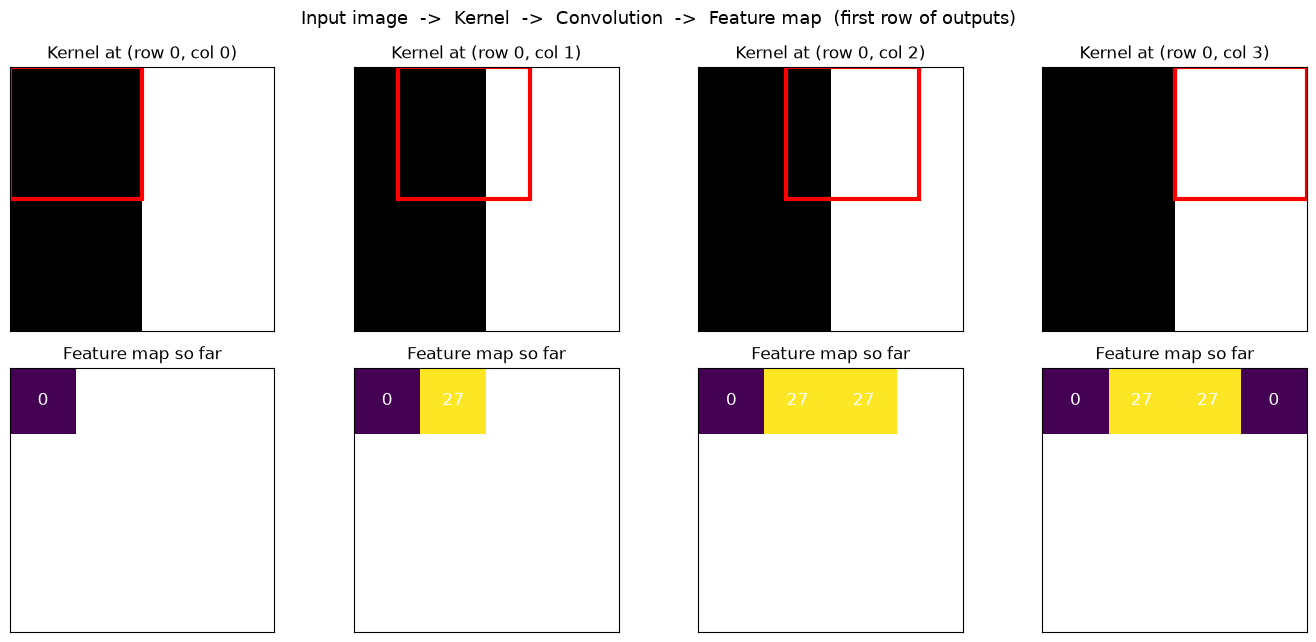

In [76]:
# Visualise the kernel sliding across the image, filling the feature map one cell at a time
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for step in range(4):
    r, c = 0, step
    axes[0, step].imshow(tiny, cmap="gray", vmin=0, vmax=9)
    axes[0, step].add_patch(plt.Rectangle((c - 0.5, r - 0.5), 3, 3, fill=False, edgecolor="red", linewidth=3))
    axes[0, step].set_title(f"Kernel at (row 0, col {c})"); axes[0, step].set_xticks([]); axes[0, step].set_yticks([])
    partial = np.full_like(feature_map, np.nan); partial[0, :step + 1] = feature_map[0, :step + 1]
    axes[1, step].imshow(partial, cmap="viridis", vmin=feature_map.min(), vmax=feature_map.max())
    for (i, j), v in np.ndenumerate(partial):
        if not np.isnan(v): axes[1, step].text(j, i, int(v), ha="center", va="center", color="white", fontsize=12)
    axes[1, step].set_title("Feature map so far"); axes[1, step].set_xticks([]); axes[1, step].set_yticks([])
plt.suptitle("Input image  ->  Kernel  ->  Convolution  ->  Feature map  (first row of outputs)", fontsize=13)
plt.tight_layout(); plt.show()

The feature map is **0 on the flat regions** (nothing to detect) and **large (27) exactly where the window straddles the dark-to-bright edge**. That is all a convolutional filter does: it answers *"how much does this patch look like my pattern?"* at every location.

### Check against PyTorch and SciPy

Note one subtlety: deep-learning "convolution" does **not** flip the kernel (that is technically *cross-correlation*). Mathematical convolution flips it. Since the kernel values are *learned*, the distinction does not matter for CNNs, but it matters when comparing libraries.

In [77]:
torch_out = F.conv2d(torch.tensor(tiny)[None, None], torch.tensor(kernel)[None, None]).squeeze().numpy()
print("Manual == torch.nn.functional.conv2d :", np.allclose(feature_map, torch_out))
print("Manual == scipy correlate2d          :", np.allclose(feature_map, signal.correlate2d(tiny, kernel, mode="valid")))

# With an asymmetric kernel, true convolution (flipped kernel) gives a different answer
asym = np.array([[1, 2, 0], [0, 0, 0], [0, 0, 0]], dtype=float)
a = conv2d_manual(tiny, asym); b = signal.convolve2d(tiny, asym, mode="valid")
print("\nAsymmetric kernel: deep-learning convolution == mathematical convolution?", np.allclose(a, b))

Manual == torch.nn.functional.conv2d : True
Manual == scipy correlate2d          : True

Asymmetric kernel: deep-learning convolution == mathematical convolution? False


### A faster vectorised version

The double loop is great for understanding but slow on real photos. The same maths without Python loops (view every window at once, then one multiply-and-sum):

In [78]:
from numpy.lib.stride_tricks import sliding_window_view
import time

def conv2d_fast(image, kernel, stride=1, padding=0):
    if padding > 0:
        image = np.pad(image, padding)
    windows = sliding_window_view(image, kernel.shape)[::stride, ::stride]      # (out_h, out_w, kh, kw)
    return np.einsum("ijkl,kl->ij", windows, kernel)

small = gray_weighted[:120, :160]
t0 = time.time(); slow = conv2d_manual(small, kernel); t_slow = time.time() - t0
t0 = time.time(); fast = conv2d_fast(small, kernel);   t_fast = time.time() - t0
print("Identical results:", np.allclose(slow, fast), f"   loop: {t_slow:.3f}s   vectorised: {t_fast:.4f}s   ({t_slow / t_fast:.0f}x faster)")

Identical results: True    loop: 0.458s   vectorised: 0.0054s   (84x faster)


## 5. Kernels/Filters on a Real Image

Different kernel numbers detect different patterns. Here are classic hand-designed filters applied to a grayscale photograph:

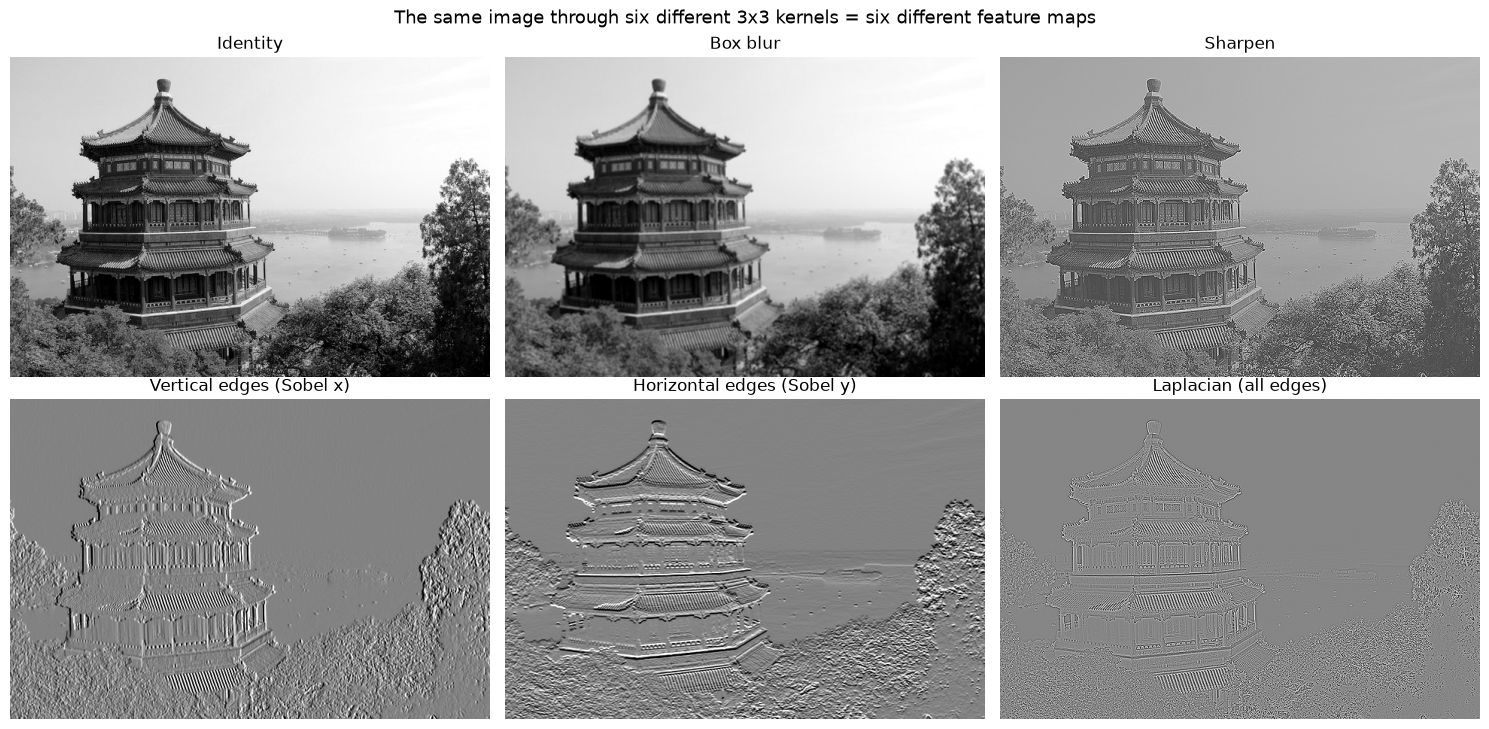

In [79]:
kernels = {
    "Identity":         np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], float),
    "Box blur":         np.ones((3, 3)) / 9,
    "Sharpen":          np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
    "Vertical edges (Sobel x)":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
    "Horizontal edges (Sobel y)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float),
    "Laplacian (all edges)":      np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float),
}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (name, k) in zip(axes.ravel(), kernels.items()):
    fm = conv2d_fast(gray_weighted, k)
    ax.imshow(fm, cmap="gray", vmin=np.percentile(fm, 1), vmax=np.percentile(fm, 99)); ax.set_title(name); ax.axis("off")
plt.suptitle("The same image through six different 3x3 kernels = six different feature maps", fontsize=13)
plt.tight_layout(); plt.show()

Each panel is a **feature map**. The Sobel-x map picks out vertical structure (the pillars and the sides of the tower), Sobel-y picks out horizontal structure (the roof edges and floor lines), the blur removes fine detail, the sharpen kernel exaggerates it, and the Laplacian responds to edges in every direction.

**The key idea of a CNN:** nobody hand-designs these numbers. The kernel values are the **learnable weights**; training adjusts them so the network discovers whichever filters are most useful for the task.

## 6. Multi-Channel Convolution and Multiple Filters

Real inputs have several channels, and each layer uses many filters:

* A filter for an input with `C_in` channels is a **3-D block** of shape `(C_in, kH, kW)`. At each position the block multiplies the patch across **all channels** and sums **everything** (all channels, all positions) into one number.
* Using `C_out` different filters produces `C_out` feature maps, stacked as the **output channels**.
* Parameters per layer = `C_out × (C_in × kH × kW) + C_out` (the last term is one bias per filter).

Implemented by hand and checked against PyTorch:

In [80]:
def conv2d_multichannel(x, weights, bias, stride=1, padding=0):
    """x: (C_in, H, W); weights: (C_out, C_in, kH, kW); bias: (C_out,) -> output (C_out, H', W')"""
    if padding > 0:
        x = np.pad(x, ((0, 0), (padding, padding), (padding, padding)))
    c_out, c_in, kh, kw = weights.shape
    windows = sliding_window_view(x, (kh, kw), axis=(1, 2))[:, ::stride, ::stride]   # (C_in, H', W', kh, kw)
    out = np.einsum("chwkl,ockl->ohw", windows, weights)                              # sum over channels AND kernel cells
    return out + bias[:, None, None]

x = t.numpy()                                                    # the RGB photo as (3, H, W) in [0, 1]
conv = nn.Conv2d(in_channels=3, out_channels=4, kernel_size=3, padding=1)
w, b = conv.weight.detach().numpy(), conv.bias.detach().numpy()

mine = conv2d_multichannel(x, w, b, padding=1)
theirs = conv(torch.tensor(x)[None]).detach().numpy()[0]
print("Input  shape (C_in, H, W) :", x.shape)
print("Filter bank shape (C_out, C_in, kH, kW):", w.shape)
print("Output shape (C_out, H', W'):", mine.shape)
print("Manual == nn.Conv2d:", np.allclose(mine, theirs, atol=1e-5))
print(f"\nParameters: {sum(p.numel() for p in conv.parameters())}  =  4 x (3 x 3 x 3) + 4  =  {4 * 27 + 4}")

Input  shape (C_in, H, W) : (3, 427, 640)
Filter bank shape (C_out, C_in, kH, kW): (4, 3, 3, 3)
Output shape (C_out, H', W'): (4, 427, 640)
Manual == nn.Conv2d: True

Parameters: 112  =  4 x (3 x 3 x 3) + 4  =  112


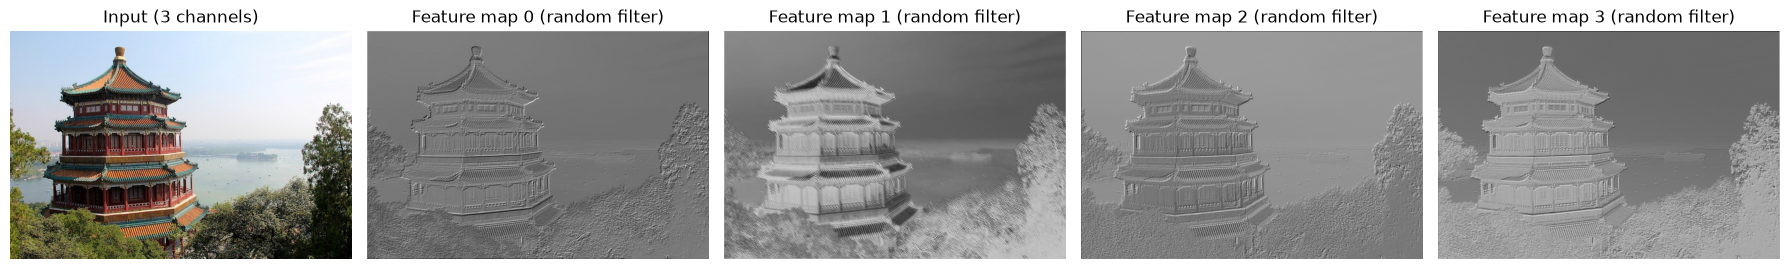

In [81]:
fig, ax = plt.subplots(1, 5, figsize=(18, 3.4))
ax[0].imshow(img); ax[0].set_title("Input (3 channels)")
for k in range(4):
    ax[k + 1].imshow(mine[k], cmap="gray"); ax[k + 1].set_title(f"Feature map {k} (random filter)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 7. Stride and Padding

* **Stride** = how many pixels the kernel jumps each step. Stride 1 visits every position; **stride 2 skips every other one**, shrinking the output (a cheap way to downsample).
* **Padding** = extra border (usually zeros) added around the image. Without it the output shrinks and edge pixels are used far less often than central ones. With the right padding the output keeps the input size ("same" padding, `p = (k-1)/2` for odd `k`).

**Output size formula** (per spatial dimension): 

`out = floor( (n + 2p − k) / s ) + 1`

with input size `n`, kernel `k`, padding `p`, stride `s`.

In [82]:
def out_size(n_in, k, p=0, s=1):
    return (n_in + 2 * p - k) // s + 1

rows = []
for k, p, s in [(3, 0, 1), (3, 1, 1), (5, 0, 1), (5, 2, 1), (3, 0, 2), (3, 1, 2), (7, 3, 2)]:
    formula = out_size(28, k, p, s)
    torch_size = nn.Conv2d(1, 1, k, stride=s, padding=p)(torch.zeros(1, 1, 28, 28)).shape[-1]
    rows.append((k, p, s, formula, torch_size, formula == torch_size))
print(f"{'kernel':>6} {'padding':>8} {'stride':>7} | {'formula':>8} {'PyTorch':>8} {'match':>6}      (input is 28 x 28)")
for r in rows: print(f"{r[0]:>6} {r[1]:>8} {r[2]:>7} | {r[3]:>8} {r[4]:>8} {str(r[5]):>6}")

kernel  padding  stride |  formula  PyTorch  match      (input is 28 x 28)
     3        0       1 |       26       26   True
     3        1       1 |       28       28   True
     5        0       1 |       24       24   True
     5        2       1 |       28       28   True
     3        0       2 |       13       13   True
     3        1       2 |       14       14   True
     7        3       2 |       14       14   True


Layer |  no padding (p=0) | 'same' padding (p=1)
    1 |                26 |                   28
    2 |                24 |                   28
    3 |                22 |                   28
    4 |                20 |                   28
    5 |                18 |                   28
    6 |                16 |                   28
Times used  ->  corner / edge / interior pixel
  no padding : 1 / 3 / 9
  padding = 1: 4 / 6 / 9


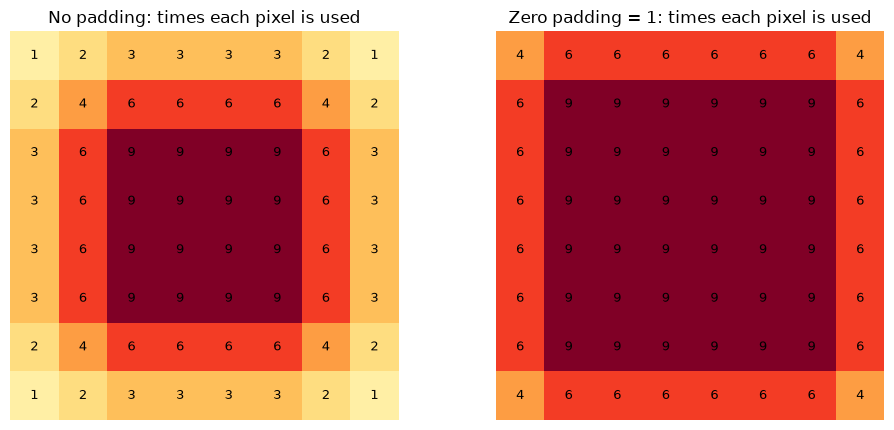

In [83]:
# Effect of padding on shrinking: apply a 3x3 conv six times in a row to a 28x28 image
size_valid, size_same = 28, 28
print("Layer |  no padding (p=0) | 'same' padding (p=1)")
for layer in range(1, 7):
    size_valid, size_same = out_size(size_valid, 3, 0, 1), out_size(size_same, 3, 1, 1)
    print(f"{layer:>5} | {size_valid:>17} | {size_same:>20}")

# Border effect: how many output positions use each input pixel?  (3x3 kernel, stride 1, 8x8 image)
def coverage(n, k, p):
    cnt = np.zeros((n + 2 * p, n + 2 * p))
    out = n + 2 * p - k + 1
    for i in range(out):
        for j in range(out):
            cnt[i:i + k, j:j + k] += 1          # this output position uses a k x k block of the (padded) input
    return cnt[p:p + n, p:p + n]                 # keep only the real (non-padding) pixels

count_nopad, count_pad = coverage(8, 3, 0), coverage(8, 3, 1)
print("Times used  ->  corner / edge / interior pixel")
print(f"  no padding : {int(count_nopad[0, 0])} / {int(count_nopad[0, 3])} / {int(count_nopad[3, 3])}")
print(f"  padding = 1: {int(count_pad[0, 0])} / {int(count_pad[0, 3])} / {int(count_pad[3, 3])}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
for a, cnt, ttl in [(ax[0], count_nopad, "No padding"), (ax[1], count_pad, "Zero padding = 1")]:
    a.imshow(cnt, cmap="YlOrRd", vmin=0, vmax=9)
    for (i, j), v in np.ndenumerate(cnt): a.text(j, i, int(v), ha="center", va="center", fontsize=9)
    a.set_title(f"{ttl}: times each pixel is used"); a.axis("off")
plt.tight_layout(); plt.show()

Without padding, a corner pixel is used by only **1** output and a border pixel by 2–3, while interior pixels are used by **9**, so information near the border is under-used. With padding = 1 corners are used 4 times and border pixels 6 times: much better, though still fewer than the interior's 9. Padding therefore *reduces* (it does not remove) the border disadvantage, and it also preserves the spatial size.

In [84]:
# Stride demonstration with the tiny edge image: stride 1 vs 2, padding 0 vs 1
for s, p in [(1, 0), (1, 1), (2, 0), (2, 1)]:
    fm = conv2d_manual(tiny, kernel, stride=s, padding=p)
    print(f"stride={s}, padding={p} -> feature map shape {fm.shape}")
    print(fm.astype(int)); print()

stride=1, padding=0 -> feature map shape (4, 4)
[[ 0 27 27  0]
 [ 0 27 27  0]
 [ 0 27 27  0]
 [ 0 27 27  0]]

stride=1, padding=1 -> feature map shape (6, 6)
[[  0   0  18  18   0 -18]
 [  0   0  27  27   0 -27]
 [  0   0  27  27   0 -27]
 [  0   0  27  27   0 -27]
 [  0   0  27  27   0 -27]
 [  0   0  18  18   0 -18]]

stride=2, padding=0 -> feature map shape (2, 2)
[[ 0 27]
 [ 0 27]]

stride=2, padding=1 -> feature map shape (3, 3)
[[ 0 18  0]
 [ 0 27  0]
 [ 0 27  0]]



**Look closely at the `padding=1` maps.** The last column contains **negative** values (−18, −27) that were not there before. The zero border looks like a dark region sitting next to the bright right edge of the image, so the vertical-edge kernel reports an "edge" there, with the opposite sign. Zero padding preserves the size, but it can create **artificial responses at the border**. (Alternatives such as reflect or replicate padding avoid this; zero padding is simply the common default.)

## 8. Receptive Field

The **receptive field** of a unit is the region of the *original input image* that can influence its value. In the first layer it is just the kernel size (3×3). But stacking layers makes it grow, which is how a CNN goes from "tiny edges" to "whole objects".

Tracking two quantities layer by layer: the receptive field size `r` and the **jump** `j` (distance in input pixels between adjacent units):

* `r_out = r_in + (k − 1) × j_in`
* `j_out = j_in × s`

starting from `r = 1, j = 1` at the input.

In [85]:
def receptive_field(layers):
    r, j = 1, 1
    rows = []
    for name, k, s in layers:
        r = r + (k - 1) * j
        j = j * s
        rows.append((name, k, s, r, j))
    return rows

stack = [("conv3x3", 3, 1), ("conv3x3", 3, 1), ("maxpool2x2", 2, 2), ("conv3x3", 3, 1), ("conv3x3", 3, 1), ("maxpool2x2", 2, 2), ("conv3x3", 3, 1)]
print(f"{'layer':<12} {'k':>2} {'s':>2} | {'receptive field':>16} {'jump':>5}")
for name, k, s, r, j in receptive_field(stack):
    print(f"{name:<12} {k:>2} {s:>2} | {r:>9} x {r:<4} {j:>5}")

layer         k  s |  receptive field  jump
conv3x3       3  1 |         3 x 3        1
conv3x3       3  1 |         5 x 5        1
maxpool2x2    2  2 |         6 x 6        2
conv3x3       3  1 |        10 x 10       2
conv3x3       3  1 |        14 x 14       2
maxpool2x2    2  2 |        16 x 16       4
conv3x3       3  1 |        24 x 24       4


**Empirical check.** Instead of trusting the formula, measure it: push a gradient back from the *centre* output unit and see which input pixels receive a non-zero gradient. (Average pooling and all-ones weights are used so that no gradient is accidentally zeroed. Max-pooling only passes gradient to one pixel per window, so its *effective* field is data-dependent even though the theoretical span is the same.)

In [86]:
def measure_rf(layer_specs, size=64):
    mods = []
    for name, k, s in layer_specs:
        if name.startswith("conv"):
            c = nn.Conv2d(1, 1, k, stride=s, bias=False); nn.init.constant_(c.weight, 1.0); mods.append(c)
        else:
            mods.append(nn.AvgPool2d(k, s))
    net = nn.Sequential(*mods)
    x = torch.zeros(1, 1, size, size, requires_grad=True)
    out = net(x)
    ci, cj = out.shape[2] // 2, out.shape[3] // 2
    out[0, 0, ci, cj].backward()
    nz = (x.grad[0, 0] != 0).nonzero()
    return int(nz[:, 0].max() - nz[:, 0].min() + 1), int(nz[:, 1].max() - nz[:, 1].min() + 1)

print(f"{'#':>2} {'last layer added':<18} {'formula':>8} {'measured (h x w)':>18}   match")
for i in range(1, len(stack) + 1):
    f = receptive_field(stack[:i])[-1][3]
    h, w = measure_rf(stack[:i])
    print(f"{i:>2} {stack[i - 1][0]:<18} {f:>8} {h:>8} x {w:<8}   {f == h == w}")

 # last layer added    formula   measured (h x w)   match
 1 conv3x3                   3        3 x 3          True
 2 conv3x3                   5        5 x 5          True
 3 maxpool2x2                6        6 x 6          True
 4 conv3x3                  10       10 x 10         True
 5 conv3x3                  14       14 x 14         True
 6 maxpool2x2               16       16 x 16         True
 7 conv3x3                  24       24 x 24         True


The measured and theoretical values agree. Notice how two stacked 3×3 convolutions see a **5×5** region using fewer weights (2 × 9 = 18 per input/output channel pair) than one 5×5 kernel (25). That is why modern CNNs prefer stacks of small kernels.

## 9. Pooling

**Pooling** shrinks a feature map by summarising each small window with **one number**:

* **Max pooling** keeps the largest value in the window ("was the feature detected anywhere in here?").
* **Average pooling** keeps the mean.

It has **no learnable parameters**. Typical use: a 2×2 window with stride 2, which halves height and width (4× fewer values), reduces computation, and makes the representation less sensitive to exact positions.

In [87]:
def pool2d_manual(x, k=2, stride=2, mode="max"):
    H, W = x.shape
    out_h, out_w = (H - k) // stride + 1, (W - k) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            win = x[i * stride:i * stride + k, j * stride:j * stride + k]
            out[i, j] = win.max() if mode == "max" else win.mean()
    return out

fmap = np.array([[1, 3, 2, 1],
                 [4, 6, 5, 0],
                 [7, 2, 9, 8],
                 [1, 0, 3, 4]], float)
print("Feature map (4 x 4):\n", fmap.astype(int))
print("\nMax pool 2x2, stride 2:\n", pool2d_manual(fmap, mode="max").astype(int))
print("\nAverage pool 2x2, stride 2:\n", pool2d_manual(fmap, mode="avg"))

ft = torch.tensor(fmap)[None, None]
print("\nMatches PyTorch max-pool :", np.allclose(pool2d_manual(fmap, mode="max"), F.max_pool2d(ft, 2).squeeze().numpy()))
print("Matches PyTorch avg-pool :", np.allclose(pool2d_manual(fmap, mode="avg"), F.avg_pool2d(ft, 2).squeeze().numpy()))

Feature map (4 x 4):
 [[1 3 2 1]
 [4 6 5 0]
 [7 2 9 8]
 [1 0 3 4]]

Max pool 2x2, stride 2:
 [[6 5]
 [7 9]]

Average pool 2x2, stride 2:
 [[3.5 2. ]
 [2.5 6. ]]

Matches PyTorch max-pool : True
Matches PyTorch avg-pool : True


**Does pooling really add robustness to small shifts?** Test it instead of assuming it. Take a Fashion-MNIST image, shift it by one pixel, and measure how much the representation changes *relative to its own size*, before and after pooling:

In [88]:
def relative_change(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + 1e-9)

edge_k = kernels["Vertical edges (Sobel x)"]
rows = []
for idx in range(200):
    im = X_train[idx].astype(float) / 255
    shifted = np.roll(im, 1, axis=1)                       # shift one pixel to the right
    fm_a = np.maximum(conv2d_fast(im, edge_k, padding=1), 0)       # conv + ReLU
    fm_b = np.maximum(conv2d_fast(shifted, edge_k, padding=1), 0)
    pooled_a, pooled_b = pool2d_manual(fm_a), pool2d_manual(fm_b)
    rows.append((relative_change(fm_a, fm_b), relative_change(pooled_a, pooled_b)))
rows = np.array(rows)
print(f"Average relative change after a 1-pixel shift (200 images):")
print(f"  feature map, before pooling : {rows[:, 0].mean():.3f}")
print(f"  after 2x2 max pooling       : {rows[:, 1].mean():.3f}")
print(f"  pooling reduced the change in {np.mean(rows[:, 1] < rows[:, 0]):.0%} of the images")

Average relative change after a 1-pixel shift (200 images):
  feature map, before pooling : 0.946
  after 2x2 max pooling       : 0.691
  pooling reduced the change in 100% of the images


**Reading the result.** A one-pixel shift changes the raw feature map a lot (about 95% relative change, because the edges themselves move), and 2×2 max pooling reduces that to about 69%, in every one of the 200 images. So pooling **does** buy some tolerance to small shifts, but it is far from complete invariance: it softens position sensitivity rather than removing it. (The numbers come from this run on 200 images; a different filter or shift size would give different values.)

## 10. Flattening and Fully Connected Layers

After the convolution and pooling stages we have a stack of feature maps with shape `(C, H, W)`. A **fully connected (dense / linear) layer** needs a flat vector, so we **flatten**: unroll the `C × H × W` numbers into one long vector.

A fully connected layer then computes `y = W·x + b`: **every** input number is connected to **every** output unit, each connection has its own learnable weight. For the final classification layer, each output unit is a class score (a *logit*).

Both steps by hand, checked against PyTorch:

In [89]:
feat = np.random.default_rng(0).normal(size=(8, 5, 5))        # pretend: 8 feature maps of size 5 x 5
flat = feat.reshape(-1)                                          # flatten
print("feature maps (C, H, W):", feat.shape, " ->  flattened vector length:", flat.shape[0], "= 8 x 5 x 5")

fc = nn.Linear(200, 10)
W, b = fc.weight.detach().numpy(), fc.bias.detach().numpy()
logits_manual = W @ flat + b
logits_torch = fc(torch.tensor(flat, dtype=torch.float32)).detach().numpy()
print("Manual W @ x + b == nn.Linear:", np.allclose(logits_manual, logits_torch, atol=1e-5))
print(f"Parameters in this single FC layer: {W.size} weights + {b.size} biases = {W.size + b.size}")

probs = np.exp(logits_manual - logits_manual.max()); probs /= probs.sum()
print("\nSoftmax turns the 10 logits into probabilities that sum to", round(probs.sum(), 3))

feature maps (C, H, W): (8, 5, 5)  ->  flattened vector length: 200 = 8 x 5 x 5
Manual W @ x + b == nn.Linear: True
Parameters in this single FC layer: 2000 weights + 10 biases = 2010

Softmax turns the 10 logits into probabilities that sum to 1.0


## 11. The Complete Pipeline: Shapes Layer by Layer

Everything together in one small CNN for 28×28 grayscale images:

`Input → Conv(1→8, 3×3) → ReLU → MaxPool → Conv(8→16, 3×3) → ReLU → MaxPool → Flatten → Linear → 10 class scores`

Tracking the shape of the data and the number of parameters at every step:

In [90]:
class TinyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, 3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(16 * 7 * 7, 10)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        return self.fc(x.flatten(1))

model = TinyCNN()
x = torch.from_numpy(X_train[:1]).float().div(255).unsqueeze(1)      # one image, shape (1, 1, 28, 28)

rows = [("Input", tuple(x.shape), 0)]
h = x
for name, layer in [("conv1 (1->8, 3x3, pad 1)", model.conv1), ("ReLU", nn.ReLU()), ("maxpool 2x2", model.pool),
                    ("conv2 (8->16, 3x3, pad 1)", model.conv2), ("ReLU", nn.ReLU()), ("maxpool 2x2", model.pool),
                    ("flatten", nn.Flatten()), ("fc (784 -> 10)", model.fc)]:
    h = layer(h)
    rows.append((name, tuple(h.shape), sum(p.numel() for p in layer.parameters())))
print(f"{'Layer':<28} {'Output shape (N,C,H,W)':<26} {'Parameters':>10}")
for name, shape, params in rows: print(f"{name:<28} {str(shape):<26} {params:>10,}")
total = sum(p.numel() for p in model.parameters())
conv_params = sum(p.numel() for m in [model.conv1, model.conv2] for p in m.parameters())
print(f"\nTotal parameters: {total:,}   (conv layers: {conv_params:,} = {conv_params / total:.1%}   |   fully connected: {total - conv_params:,} = {(total - conv_params) / total:.1%})")

Layer                        Output shape (N,C,H,W)     Parameters
Input                        (1, 1, 28, 28)                      0
conv1 (1->8, 3x3, pad 1)     (1, 8, 28, 28)                     80
ReLU                         (1, 8, 28, 28)                      0
maxpool 2x2                  (1, 8, 14, 14)                      0
conv2 (8->16, 3x3, pad 1)    (1, 16, 14, 14)                 1,168
ReLU                         (1, 16, 14, 14)                     0
maxpool 2x2                  (1, 16, 7, 7)                       0
flatten                      (1, 784)                            0
fc (784 -> 10)               (1, 10)                         7,850

Total parameters: 9,098   (conv layers: 1,248 = 13.7%   |   fully connected: 7,850 = 86.3%)


Two things stand out:

1. Spatial size **shrinks** (28 → 14 → 7) while the number of channels **grows** (1 → 8 → 16). The network trades "where" detail for "what" detail.
2. **Convolutional layers are cheap in parameters** because the same small kernel is reused at every position (*weight sharing*). In *this* network the fully connected layer holds far more parameters (7,850) than both conv layers combined (1,248), because every flattened feature connects to every class. (In deeper networks with many channels the balance can reverse, since conv layers with hundreds of channels also get large.)

## 12. Watching a CNN Learn Its Own Filters

Now let the network *discover* the kernels instead of hand-designing them. Training this tiny CNN on a subset of Fashion-MNIST (kept small so it runs quickly on a CPU):

In [91]:
Xtr = torch.from_numpy(X_train[:6000]).float().div(255).unsqueeze(1); ytr = torch.from_numpy(y_train[:6000])
Xte = torch.from_numpy(X_test[:2000]).float().div(255).unsqueeze(1);  yte = torch.from_numpy(y_test[:2000])

torch.manual_seed(0)
model = TinyCNN()
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
w_before = model.conv1.weight.detach().clone()

for epoch in range(1, 6):
    model.train(); perm = torch.randperm(len(Xtr))
    for i in range(0, len(Xtr), 64):
        idx = perm[i:i + 64]
        opt.zero_grad(); loss = F.cross_entropy(model(Xtr[idx]), ytr[idx]); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad(): acc = (model(Xte).argmax(1) == yte).float().mean().item()
    print(f"epoch {epoch}: last batch loss {loss.item():.3f}   test accuracy (2,000 images) {acc:.3f}")

epoch 1: last batch loss 0.632   test accuracy (2,000 images) 0.748
epoch 2: last batch loss 0.469   test accuracy (2,000 images) 0.816
epoch 3: last batch loss 0.350   test accuracy (2,000 images) 0.805
epoch 4: last batch loss 0.354   test accuracy (2,000 images) 0.830
epoch 5: last batch loss 0.479   test accuracy (2,000 images) 0.844


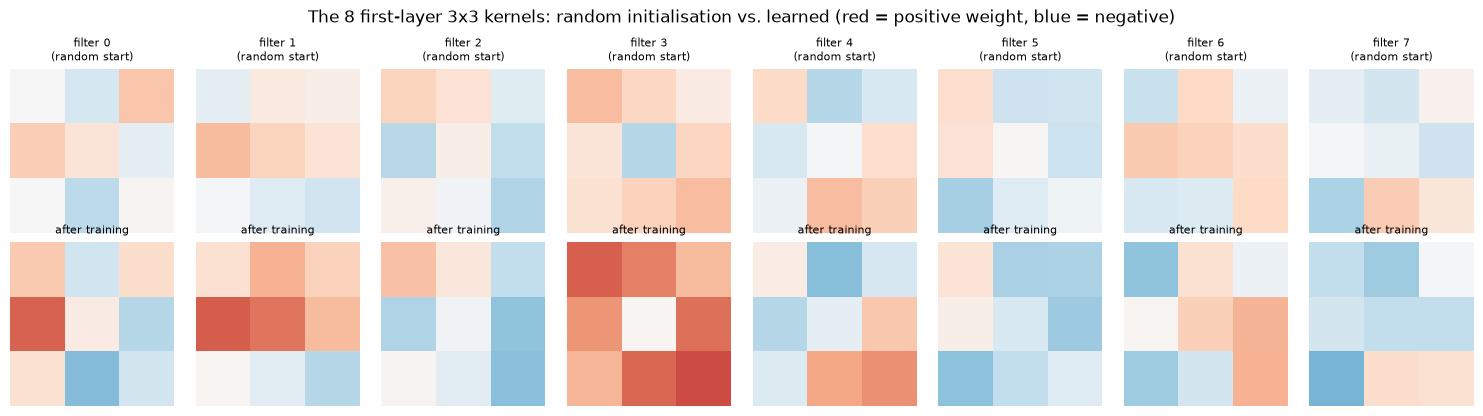

Mean absolute change of the kernel weights during training: 0.144356831908226


In [92]:
w_after = model.conv1.weight.detach()
fig, axes = plt.subplots(2, 8, figsize=(15, 4.2))
for k in range(8):
    axes[0, k].imshow(w_before[k, 0], cmap="RdBu", vmin=-1, vmax=1); axes[0, k].set_title(f"filter {k}\n(random start)", fontsize=8); axes[0, k].axis("off")
    axes[1, k].imshow(w_after[k, 0], cmap="RdBu", vmin=-1, vmax=1); axes[1, k].set_title("after training", fontsize=8); axes[1, k].axis("off")
plt.suptitle("The 8 first-layer 3x3 kernels: random initialisation vs. learned (red = positive weight, blue = negative)")
plt.tight_layout(); plt.show()
print("Mean absolute change of the kernel weights during training:", float((w_after - w_before).abs().mean()))

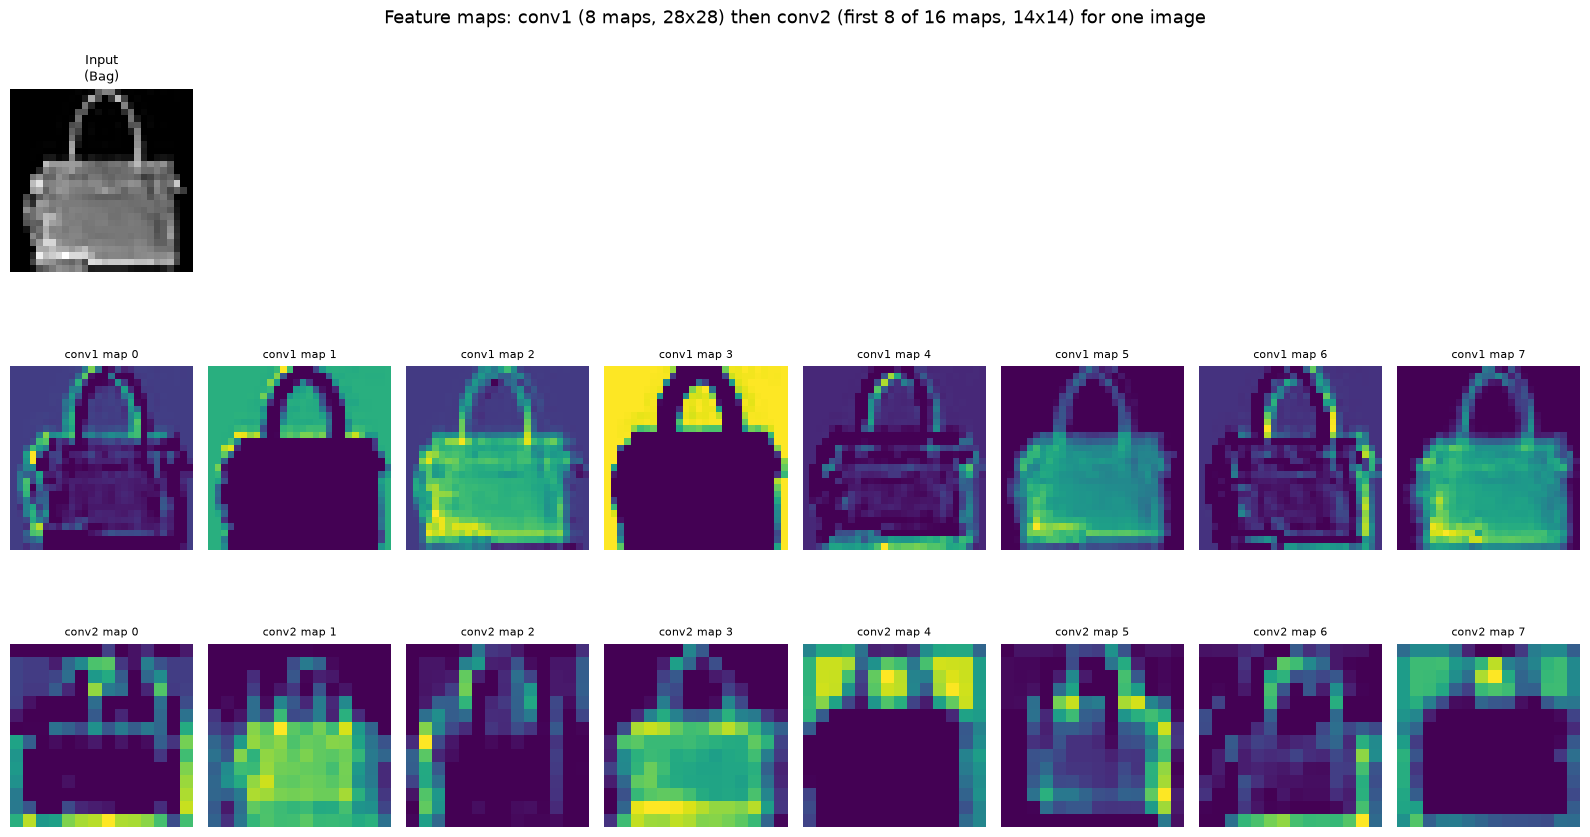

conv1 feature maps: (8, 28, 28) -> pooled: (8, 14, 14) | conv2 feature maps: (16, 14, 14) -> pooled: (16, 7, 7)


In [93]:
# Feature maps of one image at each stage
img_idx = 7
sample = Xte[img_idx:img_idx + 1]
with torch.no_grad():
    f1 = F.relu(model.conv1(sample)); p1 = model.pool(f1)
    f2 = F.relu(model.conv2(p1));     p2 = model.pool(f2)

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(3, 8)
ax = fig.add_subplot(gs[0, 0]); ax.imshow(sample[0, 0], cmap="gray"); ax.set_title(f"Input\n({FMNIST_CLASSES[yte[img_idx]]})", fontsize=9); ax.axis("off")
for k in range(8):
    a = fig.add_subplot(gs[1, k]); a.imshow(f1[0, k], cmap="viridis"); a.set_title(f"conv1 map {k}", fontsize=8); a.axis("off")
for k in range(8):
    a = fig.add_subplot(gs[2, k]); a.imshow(f2[0, k], cmap="viridis"); a.set_title(f"conv2 map {k}", fontsize=8); a.axis("off")
plt.suptitle("Feature maps: conv1 (8 maps, 28x28) then conv2 (first 8 of 16 maps, 14x14) for one image", fontsize=13)
plt.tight_layout(); plt.show()
print("conv1 feature maps:", tuple(f1.shape[1:]), "-> pooled:", tuple(p1.shape[1:]), "| conv2 feature maps:", tuple(f2.shape[1:]), "-> pooled:", tuple(p2.shape[1:]))